# Model Karsilastirma - Ozet Tablo

Butun `NN_*.ipynb` defterlerini calistirdiktan sonra bunu calistir.
Makale icin tablo ve grafik uretir.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

rows=[]
for jf in sorted(Path('results').glob('*.json')):
    d=json.load(open(jf))
    rows.append(d)
cols=['model','roc_auc_mean','roc_auc_std','pr_auc_mean','f1_mean','precision_mean','recall_mean','balanced_accuracy_mean','brier_mean']
tbl=pd.DataFrame(rows)[cols].sort_values('roc_auc_mean',ascending=False).reset_index(drop=True)
tbl.round(3)

,model,roc_auc_mean,roc_auc_std,pr_auc_mean,f1_mean,precision_mean,recall_mean,balanced_accuracy_mean,brier_mean
0,catboost,0.846,0.093,0.901,0.852,0.822,0.898,0.709,0.137
1,random_forest,0.842,0.092,0.906,0.857,0.870,0.850,0.682,0.132
2,xgboost,0.796,0.160,0.893,0.856,0.821,0.908,0.669,0.136
3,logistic_regression,0.778,0.045,0.866,0.812,0.818,0.832,0.676,0.151
4,stacking_ensemble,0.734,0.267,0.873,0.663,0.693,0.801,0.461,0.226
5,lightgbm,0.717,0.229,0.877,0.827,0.803,0.866,0.615,0.172
6,mlp,0.428,0.109,0.711,0.674,0.714,0.751,0.453,0.229


In [2]:
# Makale icin LaTeX tablosu
print(tbl.round(3).to_latex(index=False))

\begin{tabular}{lrrrrrrrr}
\toprule
model & roc_auc_mean & roc_auc_std & pr_auc_mean & f1_mean & precision_mean & recall_mean & balanced_accuracy_mean & brier_mean \\
\midrule
catboost & 0.846000 & 0.093000 & 0.901000 & 0.852000 & 0.822000 & 0.898000 & 0.709000 & 0.137000 \\
random_forest & 0.842000 & 0.092000 & 0.906000 & 0.857000 & 0.870000 & 0.850000 & 0.682000 & 0.132000 \\
xgboost & 0.796000 & 0.160000 & 0.893000 & 0.856000 & 0.821000 & 0.908000 & 0.669000 & 0.136000 \\
logistic_regression & 0.778000 & 0.045000 & 0.866000 & 0.812000 & 0.818000 & 0.832000 & 0.676000 & 0.151000 \\
stacking_ensemble & 0.734000 & 0.267000 & 0.873000 & 0.663000 & 0.693000 & 0.801000 & 0.461000 & 0.226000 \\
lightgbm & 0.717000 & 0.229000 & 0.877000 & 0.827000 & 0.803000 & 0.866000 & 0.615000 & 0.172000 \\
mlp & 0.428000 & 0.109000 & 0.711000 & 0.674000 & 0.714000 & 0.751000 & 0.453000 & 0.229000 \\
\bottomrule
\end{tabular}



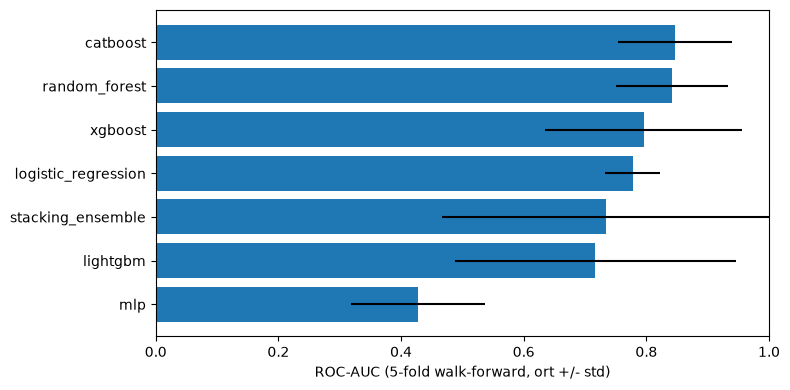

In [3]:
fig,ax=plt.subplots(figsize=(8,4))
t=tbl.sort_values('roc_auc_mean')
ax.barh(t['model'],t['roc_auc_mean'],xerr=t['roc_auc_std'])
ax.set_xlabel('ROC-AUC (5-fold walk-forward, ort +/- std)')
ax.set_xlim(0,1); plt.tight_layout(); plt.savefig('results/roc_auc_comparison.png',dpi=150); plt.show()